In [1]:
import numpy as np
import pandas as pd 
import tensorflow as tf

df_train = pd.read_csv('ECG5000_train.csv')
df_test = pd.read_csv('ECG5000_test.csv')

In [2]:
print(df_train.shape)
print(df_test.shape)
print(df_train.head())
print(df_test.head())

#The data N1 is the number of normal beats in the ECG, N2 is the anormal beats in the ECG.
#The 140 columns are the values of the ECG signal at different time points.



(7600, 141)
(1900, 141)
   0        1        2       3        4        5       6        7         8  \
0  1 -1.30300 -0.83573 -1.9336 -2.09420 -2.02840 -1.2531 -0.52638 -0.089286   
1  2  0.32288 -0.87847 -1.8023 -2.66850 -3.26550 -3.3326 -2.88000 -2.227400   
2  2  1.39340  1.59260  1.2420  0.79449  0.19577 -0.3156 -0.58053 -0.945020   
3  1 -3.52270 -5.02610 -4.3613 -4.10570 -3.10420 -1.8178 -1.39840 -1.070100   
4  1 -1.91820 -3.22510 -3.4652 -4.00800 -3.87030 -3.3581 -2.28540 -1.728500   

         9  ...      131     132     133      134       135      136      137  \
0 -0.07557  ... -1.45820 -1.6676 -1.5977 -1.67930 -1.677200 -1.69370 -1.79410   
1 -1.54360  ... -1.23050 -1.7218 -2.1953 -2.74890 -3.446500 -3.66210 -3.01820   
2 -1.23350  ... -1.90850 -2.5295 -3.0614 -3.50370 -3.900400 -4.24600 -4.13380   
3 -0.40691  ...  0.83038  1.0084  1.1830  0.94636  0.952130  0.79343  0.84741   
4 -1.42220  ...  1.77690  1.5029  1.1651  0.46073  0.019172 -0.32739 -0.48051   

       138    

In [3]:
df_train['0'].value_counts() 

0
1    4427
2    2683
4     306
3     149
5      35
Name: count, dtype: int64

# TRAINING AND VALIDATION SETS

In [4]:
datos_train = df_train.values
datos_test = df_test.values

cat_train = datos_train[:,0]
cat_test = datos_test[:,0]

#We therefore have 5 classes in the dataset, and we need to make a subset of the data for each class.

x_train_1 = datos_train[cat_train==1,1:] #with this we are selecting the rows that have the category 1 and so on for the others.
x_train_2 = datos_train[cat_train==2,1:]
x_train_3 = datos_train[cat_train==3,1:]
x_train_4 = datos_train[cat_train==4,1:]
x_train_5 = datos_train[cat_train==5,1:]

x_test_1 = datos_test[cat_test==1,1:]
x_test_2 = datos_test[cat_test==2,1:]
x_test_3 = datos_test[cat_test==3,1:]
x_test_4 = datos_test[cat_test==4,1:]
x_test_5 = datos_test[cat_test==5,1:]

In [5]:
import matplotlib.pyplot as plt
import numpy as np

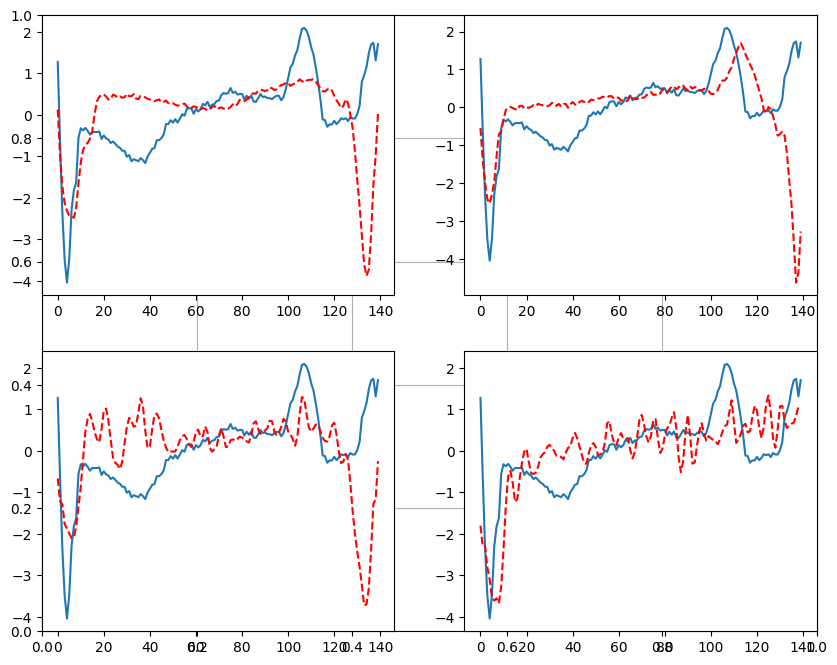

In [6]:
#SHOWING THE NORMAL AND ANORMAL ECG SIGNALS

ind = 10
normal = x_train_1[ind]
anormal_2 = x_train_2[ind]
anormal_3 = x_train_3[ind]
anormal_4 = x_train_4[ind]
anormal_5 = x_train_5[ind]

plt.figure(figsize=(10,8))
plt.grid()
plt.subplot(2,2,1)
plt.plot(np.arange(140), normal)
plt.plot(np.arange(140), anormal_2, 'r--')
plt.subplot(2,2,2)
plt.plot(np.arange(140), normal)
plt.plot(np.arange(140), anormal_3, 'r--')
plt.subplot(2,2,3)
plt.plot(np.arange(140), normal)
plt.plot(np.arange(140), anormal_4, 'r--')
plt.subplot(2,2,4)
plt.plot(np.arange(140), normal)
plt.plot(np.arange(140), anormal_5, 'r--')


In [7]:
#NORMALIZING THE DATA

from sklearn.preprocessing import MinMaxScaler
min_max_scaler = MinMaxScaler() #This is to normalize the data. It takes each data, substracts the maximum, the minimun and each point and divides by the difference between the maximum and the minimum.
#After this, the data is between 0 and 1.

x_train_1_s = min_max_scaler.fit_transform(x_train_1)
print('Minium and maximum originals: {:.1f}, {:.1f}'.format(np.min(x_train_1), np.max(x_train_1)))
print('Minimum and maximum normalized: {:.1f}, {:.1f}'.format(np.min(x_train_1_s), np.max(x_train_1_s)))

x_test_1_s = min_max_scaler.transform(x_test_1)
x_test_2_s = min_max_scaler.transform(x_test_2)
x_test_3_s = min_max_scaler.transform(x_test_3)
x_test_4_s = min_max_scaler.transform(x_test_4)
x_test_5_s = min_max_scaler.transform(x_test_5)



Minium and maximum originals: -7.1, 5.0
Minimum and maximum normalized: 0.0, 1.0


In [ ]:
# AUTOENCODER USING TENSORFLOW AND KERAS

from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense
np.random.seed(23)

dim_entry = x_train_1_s.shape[1]
entry = Input(shape=(dim_entry,))

#Encoder

encoder = Dense(32, activation='relu')(entry) #Using rellu always in the middle layers (hidden layers) of the network.
encoder = Dense(16, activation='relu')(encoder)
encoder = Dense(8, activation='relu')(encoder)

#Decoder

decoder = Dense(16, activation='relu')(encoder)
decoder = Dense(32, activation='relu')(decoder)
decoder = Dense(dim_entry, activation='sigmoid')(decoder) #Using sigmoid in the output layer to have values between 0 and 1 (probability distribution). #Thats why we normalized the data before.

#Autoencoder 

autoencoder = Model(inputs=entry, outputs=decoder)
autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 140)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         4,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 140)            │         4,620 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,484 (40.95 KB)

 Trainable params: 10,484 (40.95 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
#Defining the optimizer and the loss function

#WE USE MAE (MEAN ABSOLUTE ERROR) BECAUSE WE WANT TO MINIMIZE THE DIFFERENCE BETWEEN THE INPUT AND THE OUTPUT OF THE AUTOENCODER.

autoencoder.compile(optimizer='adam', loss='mae') #adam is a good optimizer for this kind of problems to reduce the loss function.

#Training the autoencoder
HT = autoencoder.fit(x_train_1_s, x_train_1_s, #We use the same data as input and output because we want to minimize the difference between the input and the output.
                      epochs=20, #We use 20 epochs to train the model.
                      validation_data=(x_test_1_s, x_test_1_s), #We use the test data to validate the model
                      batch_size = 512, #We use a batch size of 512 to avoid overfitting.
                      shuffle = True) # WE SHUFFLE THE DATA TO ADD RANDOMNESS TO THE TRAINING.





Epoch 1/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.1250 - val_loss: 0.1188
Epoch 2/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.1159 - val_loss: 0.1066
Epoch 3/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.1034 - val_loss: 0.0936
Epoch 4/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0907 - val_loss: 0.0826
Epoch 5/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0804 - val_loss: 0.0749
Epoch 6/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0736 - val_loss: 0.0695
Epoch 7/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0686 - val_loss: 0.0664
Epoch 8/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0655 - val_loss: 0.0645
Epoch 9/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0640 - val_loss: 0.0634
Epoch 10/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0627 - val_loss: 0.0620
Epoch 11/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0620 - val_loss: 0.0603
Epoch 12/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0601 - val_loss: 0.0586
Epoch 13/20


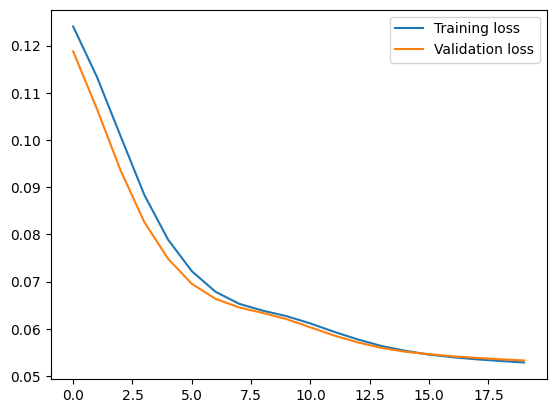

In [10]:
plt.plot(HT.history['loss'], label='Training loss')
plt.plot(HT.history['val_loss'], label='Validation loss')
plt.legend()

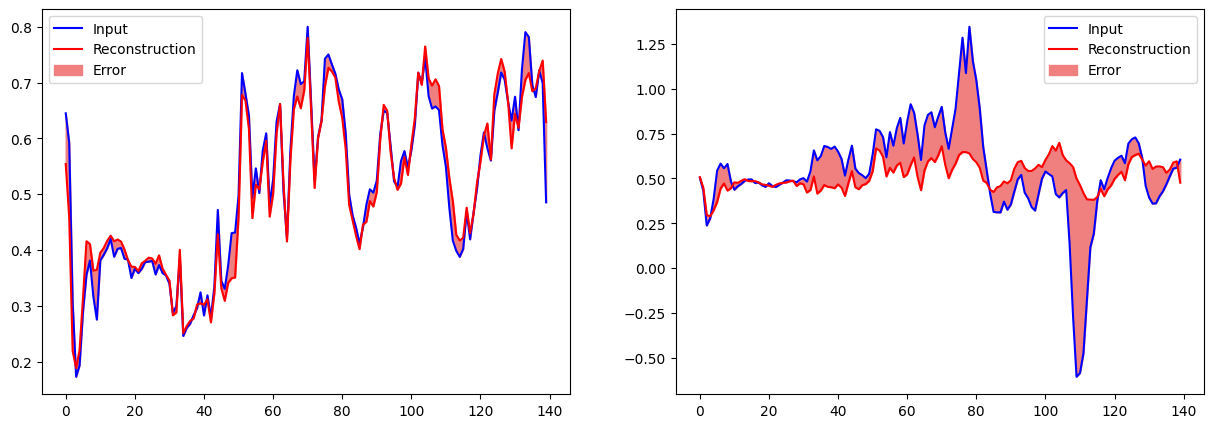

In [ ]:
rec_normal = autoencoder(x_test_1_s).numpy()
rec_anormal = autoencoder(x_test_2_s).numpy()

dato = 7
plt.figure(figsize=(15,5))
plt.subplot(1,2,1)
plt.plot(x_test_1_s[dato], 'b')
plt.plot(rec_normal[dato], 'r')
plt.fill_between(np.arange(140), rec_normal[dato], x_test_1_s[dato], color='lightcoral')
plt.legend(['Input', 'Reconstruction', 'Error'])
plt.subplot(1,2,2)
plt.plot(x_test_5_s[dato], 'b')
plt.plot(rec_anormal[dato], 'r')
plt.fill_between(np.arange(140), rec_anormal[dato], x_test_5_s[dato], color='lightcoral')
plt.legend(['Input', 'Reconstruction', 'Error'])

We can easily see that the autoenconder is doing a good job, it is not perfect, but it's what we expected in order to avoid overfitting.

35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step


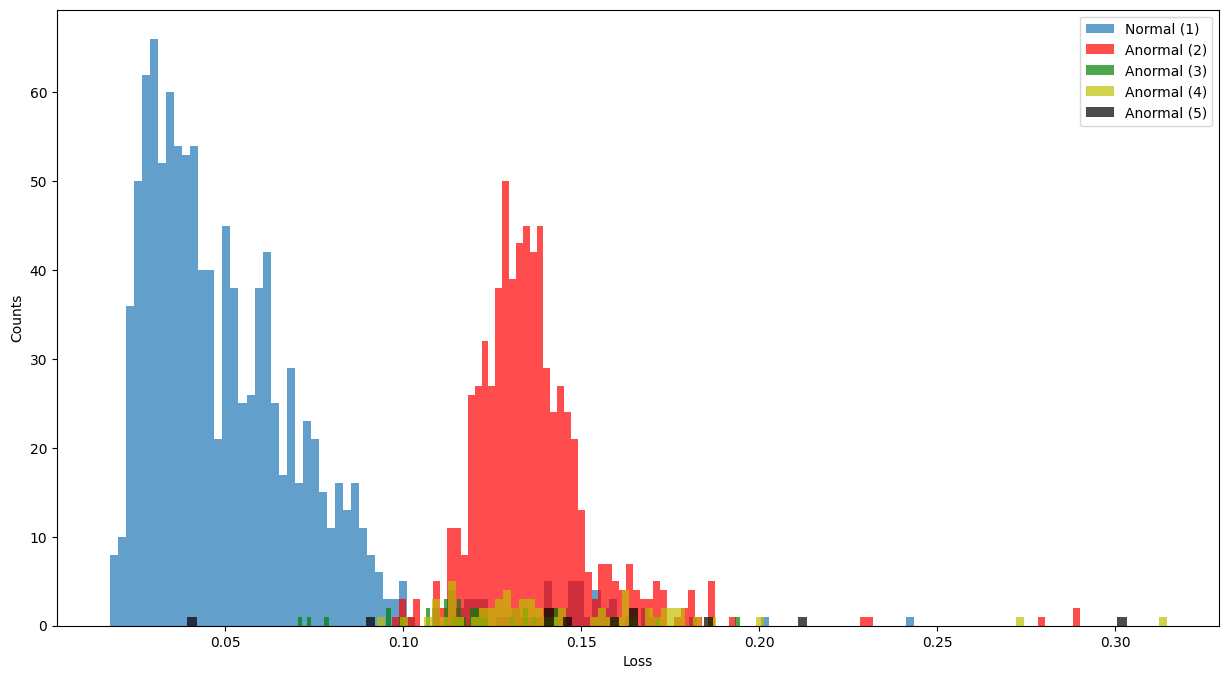

In [12]:
rec_1 = autoencoder.predict(x_test_1_s)
rec_2 = autoencoder.predict(x_test_2_s)
rec_3 = autoencoder.predict(x_test_3_s)
rec_4 = autoencoder.predict(x_test_4_s)
rec_5 = autoencoder.predict(x_test_5_s)

loss_1 = tf.keras.losses.mae(rec_1, x_test_1_s)
loss_2 = tf.keras.losses.mae(rec_2, x_test_2_s)
loss_3 = tf.keras.losses.mae(rec_3, x_test_3_s)
loss_4 = tf.keras.losses.mae(rec_4, x_test_4_s)
loss_5 = tf.keras.losses.mae(rec_5, x_test_5_s)

plt.figure(figsize=(15,8))
plt.hist(loss_1[None,:],bins = 100, alpha=0.7, label='Normal (1)')
plt.hist(loss_2[None,:],bins = 100, alpha=0.7, color = 'r', label='Anormal (2)')
plt.hist(loss_3[None,:],bins = 100, alpha=0.7, color = 'g', label='Anormal (3)')
plt.hist(loss_4[None,:],bins = 100, alpha=0.7, color = 'y', label='Anormal (4)')
plt.hist(loss_5[None,:],bins = 100, alpha=0.7, color = 'k', label='Anormal (5)')
plt.xlabel('Loss')
plt.ylabel('Counts')
plt.legend(loc='upper right')

#WITH THIS WE CAN SEE THAT THE NORMAL ECG SIGNALS HAVE A LOWER LOSS THAN THE ANORMAL ECG SIGNALS. WE CAN USE THIS TO DETECT ANORMAL ECG SIGNALS.

In [13]:
threshold = np.mean(loss_1) + np.std(loss_1)
print('Threshold: {:.2f}'.format(threshold))

Threshold: 0.08


35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 755us/step
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 885us/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step


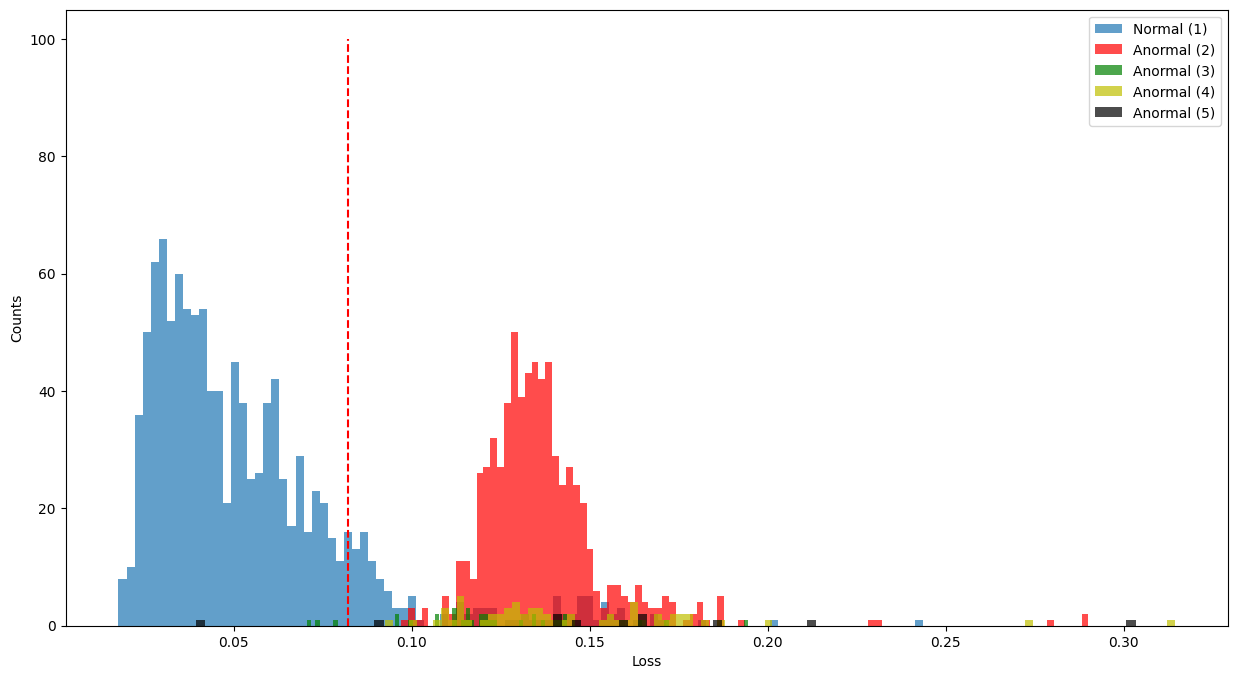

In [14]:
rec_1 = autoencoder.predict(x_test_1_s)
rec_2 = autoencoder.predict(x_test_2_s)
rec_3 = autoencoder.predict(x_test_3_s)
rec_4 = autoencoder.predict(x_test_4_s)
rec_5 = autoencoder.predict(x_test_5_s)

loss_1 = tf.keras.losses.mae(rec_1, x_test_1_s)
loss_2 = tf.keras.losses.mae(rec_2, x_test_2_s)
loss_3 = tf.keras.losses.mae(rec_3, x_test_3_s)
loss_4 = tf.keras.losses.mae(rec_4, x_test_4_s)
loss_5 = tf.keras.losses.mae(rec_5, x_test_5_s)

plt.figure(figsize=(15,8))
plt.hist(loss_1[None,:],bins = 100, alpha=0.7, label='Normal (1)')
plt.hist(loss_2[None,:],bins = 100, alpha=0.7, color = 'r', label='Anormal (2)')
plt.hist(loss_3[None,:],bins = 100, alpha=0.7, color = 'g', label='Anormal (3)')
plt.hist(loss_4[None,:],bins = 100, alpha=0.7, color = 'y', label='Anormal (4)')
plt.hist(loss_5[None,:],bins = 100, alpha=0.7, color = 'k', label='Anormal (5)')
plt.xlabel('Loss')
plt.ylabel('Counts')
plt.legend(loc='upper right')
plt.vlines(threshold, 0, 100, color='r', linestyle='--', label='Threshold') #This is the threshold that we calculated before. And now we are plotting it in the histogram.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step


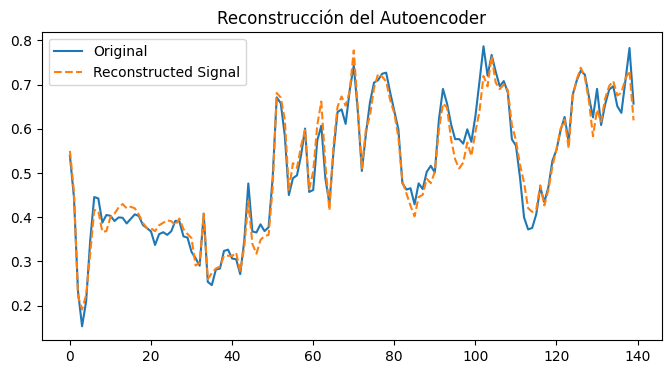

In [30]:
# WE CAN SEE THAT THE NORMAL ECG SIGNALS HAVE A LOWER LOSS THAN THE ANORMAL ECG SIGNALS. WE CAN USE THIS TO DETECT ANORMAL ECG SIGNALS.
sample_idx = np.random.randint(0, len(x_test_1_s))
original = x_test_1_s[sample_idx]
reconstructed = autoencoder.predict(original.reshape(1, -1)).flatten()

plt.figure(figsize=(8, 4))
plt.plot(original, label="Original")
plt.plot(reconstructed, label= "Reconstructed Signal", linestyle="dashed")
plt.legend()
plt.title("Reconstrucción del Autoencoder")
plt.show()


In [25]:
# Compute the reconstruction error (MAE or MSE)
reconstruction_error = np.mean(np.abs(original - reconstructed))

print(f"Reconstruction error for this sample: {reconstruction_error:.4f}")

Reconstruction error for this sample: 0.0513


In [27]:
print("Autoencoder training and evaluation completed. We can now analyze the results.")


Autoencoder training and evaluation completed. We can now analyze the results.
